# Libraries

In [1]:
import numpy as np # Linear algebra
import pandas as pd # data processing

#Visualisations Libraries
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

# Upload data 

In [2]:
data = pd.read_csv("iris.csv")
data.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
data.drop("Id", axis = 1 ,inplace= True )

In [4]:
data.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Exploratory Data Analysis
Understanding our data

In [5]:
#Data Shape below shows that our data have  columns and 150 records.
data.shape

(150, 5)

### Missing value
We need to confirm if our data doesn't have missing values using a heatmap plot so that we can work with a unique dataset. If there is a column with missing values, that column or feature will show dashes on the heatmap plot. Below the heat map is blank which means we have no missing values in our housing data. 

<AxesSubplot:>

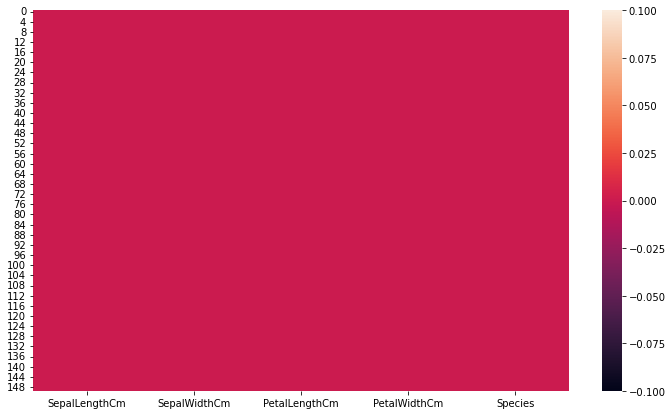

In [6]:
plt.rcParams['figure.figsize'] = (12, 7)
sns.heatmap(data.isnull()) 

**The following also confirms that our data contains no missing values and that the data type of all the features variables is float64, whereas the data type of target variable (species) is object**

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [8]:
data.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Correlation plot that shows that each feature is perfectly correlated. This is indicated by the full diagonal.** 


<AxesSubplot:>

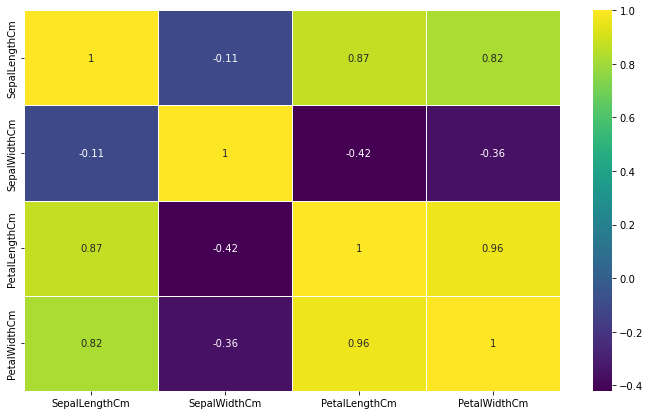

In [9]:
plt.rcParams['figure.figsize'] = (12, 7)
sns.heatmap(data.corr(), annot= True, linewidths = 0.5, cmap ='viridis')

In [10]:
data.columns

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [11]:
# data.drop("SepalLengthCm", axis = 1 ,inplace= True )

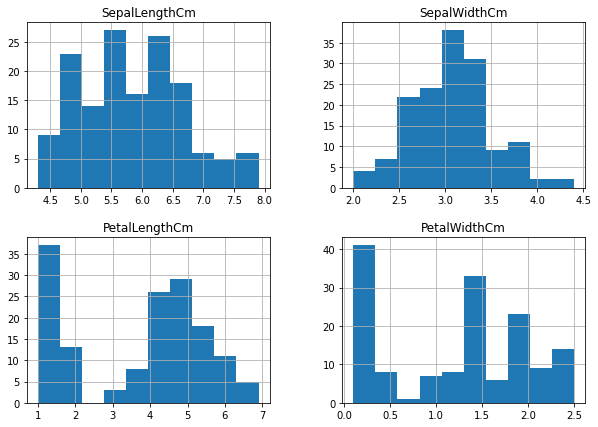

In [12]:
#Below histograms shows that some of our features are more or less normally distributed and some are not
data.hist(figsize=(10,7))
plt.show()

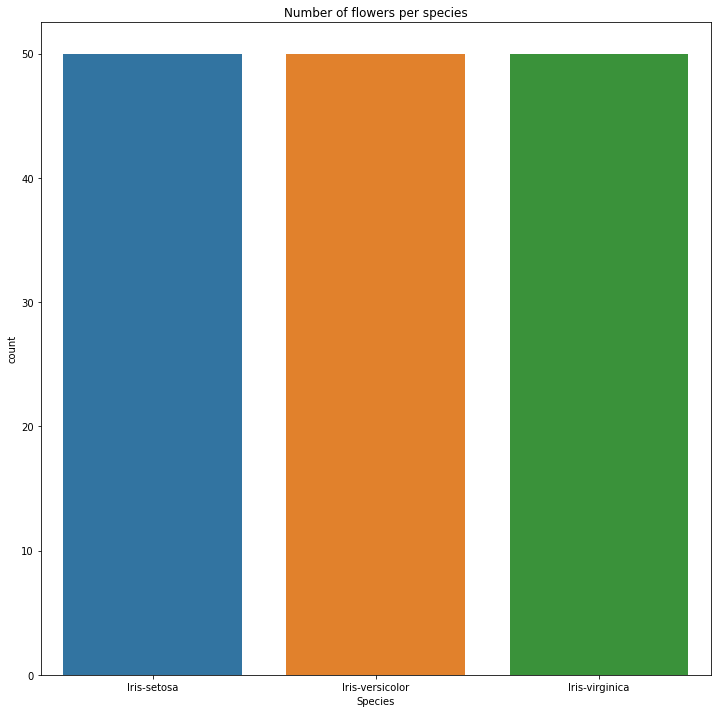

In [13]:
plt.figure(figsize = (12,12))
c_plot = sns.countplot(data.Species,order=data.Species.value_counts(ascending=False).index)
plt.title("Number of flowers per species")
plt.show()

**The histogram above shows that our data set is balanced, hence we can directly feed this into our model because it wont  be biased towards specific class. 

**What is Imbalance?** *Any dataset would be called imbalanced if there is the very high difference between the positive values and negative values. In other words, a dataset containing a huge difference in the number of records for each (any) of it's target classes is called an imbalanced dataset.*

**In our dataset we have equal number of species in each class. This clearly shows that our dataset is balanced.**

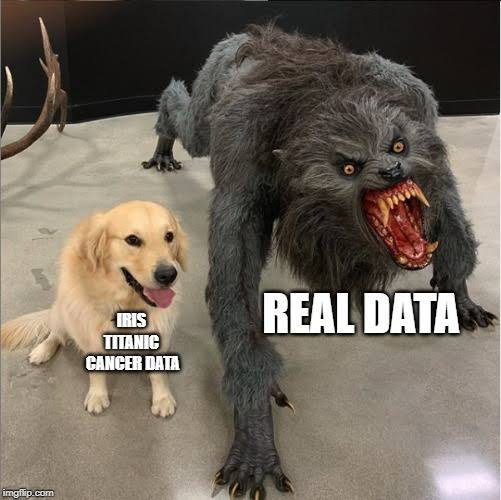

In [14]:
### converting the training 

In [15]:
species_dummy = pd.get_dummies(data["Species"])
species_dummy.head()

,Iris-setosa,Iris-versicolor,Iris-virginica
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


In [16]:
# assigned_data = data.copy()

In [17]:
data = pd.concat([data, species_dummy], axis = 1)
data.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Iris-setosa,Iris-versicolor,Iris-virginica
0,5.1,3.5,1.4,0.2,Iris-setosa,1,0,0
1,4.9,3.0,1.4,0.2,Iris-setosa,1,0,0
2,4.7,3.2,1.3,0.2,Iris-setosa,1,0,0
3,4.6,3.1,1.5,0.2,Iris-setosa,1,0,0
4,5.0,3.6,1.4,0.2,Iris-setosa,1,0,0


## Data Spliting
We will need to first split up our data into an X array that contains the features to train on and a y array with the target/label variable.
### X and y

In [18]:
X = data.drop(['Species',"Iris-setosa","Iris-versicolor","Iris-virginica"],axis=1)
y = data[["Iris-setosa","Iris-versicolor","Iris-virginica"]]

In [19]:
X.head(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


In [20]:
y.shape

(150, 3)

In [21]:
X.shape

(150, 4)

## Train Test Split

Now let's split the data into a training set and a testing set. We will train our model on the training set and then use the test set to evaluate the model.

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10,stratify=y,random_state=100)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((135, 4), (15, 4), (135, 3), (15, 3))

## Feature Scaling using normalisation
To scale our data using standardization, we will need to import the StandardScalar from the sklearn library and apply it to our dataset. 

In [24]:
from sklearn.preprocessing import MinMaxScaler
Scaling = MinMaxScaler()

In [25]:
## This will standardize our dataset by considering mean as zero and Variance as 1
X_train = Scaling.fit_transform(X_train) #Standardized X training set
X_test = Scaling.transform(X_test) #Standardized y training set

In [26]:
# Scaled x train data
print(X_train[0])

[0.47222222 0.375      0.5862069  0.58333333]


In [27]:
#25% of the data is in test set and train set have 75% of the data
print(X_train.shape)
print(X_test.shape)

(135, 4)
(15, 4)


## Data Modelling
Now we need to implement different classification models and see which one gives the best results based on the accuracy level.

*Please note: As the results  vary with each run, those seen below may not be the exact same as the report values.

In [28]:
#Acurracy library
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

**1. Neural network Model**

In [29]:
# Neural Ntework Library
from sklearn.neural_network import MLPClassifier

#Initializing the Neural network Classifier
MLPC = MLPClassifier(hidden_layer_sizes=(8,), max_iter=50000, activation='tanh')

#Training the model using the Training Dataset
MLPC.fit(X_train, y_train)

#Model Prediction using test data
y_pred_nn = MLPC.predict(X_test)

#Model Accuracy
accuracy_of_Neaural_Net = round(accuracy_score(y_test, y_pred_nn) * 100, 2)
print('Accuracy of Neural Network model : ', accuracy_of_Neaural_Net)

Accuracy of Neural Network model :  100.0


In [30]:
print(classification_report(y_test,y_pred_nn))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5
           2       1.00      1.00      1.00         5

   micro avg       1.00      1.00      1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15
 samples avg       1.00      1.00      1.00        15



**4. K - Nearest Neighbour Model**

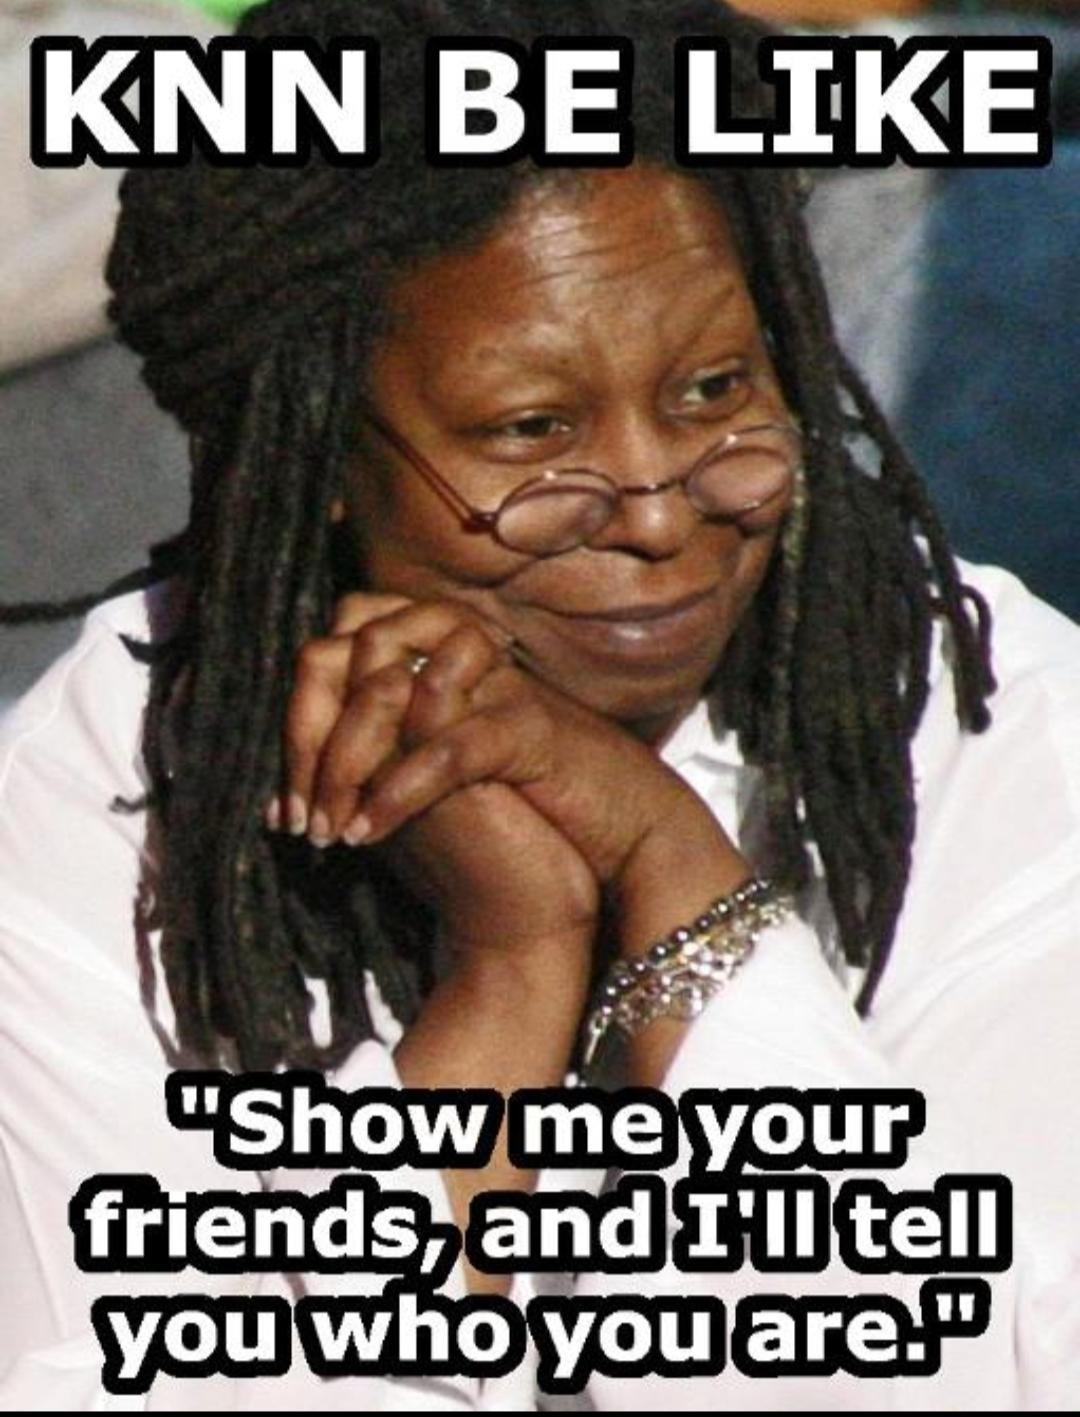

In [31]:
from IPython.display import Image
Image(filename = "KNN.png", width=400, height=400)

#### Choosing a K Value
The elbow method to pick a good K Value:

In [32]:
#Import Library for K Nearest Neighbour Model
from sklearn.neighbors import KNeighborsClassifier
error_rate = []

# Will take some time
for i in range(1,40):
    
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error Rate')

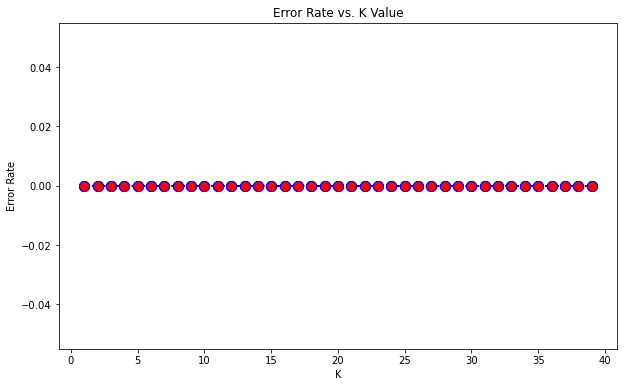

In [33]:
plt.figure(figsize=(10,6))
plt.plot(range(1,40),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

Above plot froms an elbow around K=5 the error rate just tends to hover around 0.0-0.08 Let's retrain the model with that and check the classification report!

In [34]:
#Initializing KNN model
knn_model = KNeighborsClassifier( n_neighbors=5)

#Train the model using Training Dataset
knn_model.fit(X_train, y_train)

# Prediction using test data
y_pred_knn = knn_model.predict(X_test)

# Calculate Model accuracy by comparing y_test and y_pred
accuracy_of_KNN = round( accuracy_score(y_test, y_pred_knn) * 100, 2)
print( 'Accuracy of KNN Classifier: ', accuracy_of_KNN)


Accuracy of KNN Classifier:  100.0


In [35]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5
           2       1.00      1.00      1.00         5

   micro avg       1.00      1.00      1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15
 samples avg       1.00      1.00      1.00        15



**5. Random Forest Model**

In [36]:
from sklearn.ensemble import RandomForestClassifier

In [37]:
#Import Library for Random forest Model
from sklearn.ensemble import RandomForestClassifier

#Initialize the model
rf_model = RandomForestClassifier(n_estimators= 110, criterion='entropy')

#Train the model using Training Dataset
rf_model.fit(X_train, y_train)

# Prediction using test data
y_pred_rf = rf_model.predict(X_test)

# Calculate Model accuracy by comparing y_test and y_pred
accuracy_of_rf = round( accuracy_score(y_test, y_pred_rf) * 100, 2)
print( 'Accuracy of random Frest Classifier: ', accuracy_of_rf)

Accuracy of random Frest Classifier:  100.0


In [38]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5
           2       1.00      1.00      1.00         5

   micro avg       1.00      1.00      1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15
 samples avg       1.00      1.00      1.00        15



### Model selection

The table a below shows the best performing algorithms in descending order based on highest accuracy of the last prediction of each algorithm**

In [39]:
models = pd.DataFrame({
    'Model': ['Neural network', 'Random Forest', 'K - Nearest Neighbors'],
    'Score': [accuracy_of_Neaural_Net, accuracy_of_rf, accuracy_of_KNN]})

models.sort_values(by='Score', ascending=False)

,Model,Score
0,Neural network,100.0
1,Random Forest,100.0
2,K - Nearest Neighbors,100.0


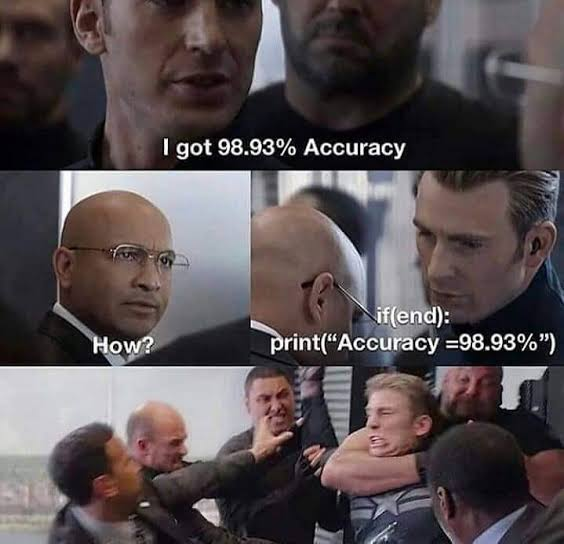